In [1]:
import numpy as np
import xarray as xr
import cftime
import pandas as pd

from scipy import signal
from scipy.ndimage import center_of_mass
from scipy.signal import hilbert, correlate
from scipy.ndimage import gaussian_filter1d

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.patches import Rectangle

import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter

In [22]:
1472282*4/1024/1024*12*(2016-1958)

3908.9518432617188

In [16]:
xr.open_dataset(r'C:\Users\jiuwe\study\data\era5\sossheig_control_monthly_highres_2D_195801_CONS_v0.1.nc')

<xarray.Dataset>
Dimensions:       (y: 1021, x: 1442, time_counter: 1)
Coordinates:
    nav_lat       (y, x) float32 ...
    nav_lon       (y, x) float32 ...
  * time_counter  (time_counter) datetime64[ns] 1958-01-16
Dimensions without coordinates: y, x
Data variables:
    sossheig      (time_counter, y, x) float32 ...
Attributes:
    Conventions:  CF-1.4
    NCO:          netCDF Operators version 4.9.2 (Homepage = http://nco.sf.ne...
    title:        Monthly mean 2D Sea Surface fields
    source:       ORAS5 - backward extension (ECMWF)
    institution:  European Centre for Medium-Range Weather Forecasts (ECMWF) ...
    reference:    https://www.ecmwf.int/en/research/climate-reanalysis/ocean-...

In [12]:
sst = xr.open_dataset('sst.nc').sel(lon=slice(120, 280)).sst.loc['1900':'2024']
sst_cli = sst.groupby(sst.time.dt.month).mean()
sst_ano = sst.groupby(sst.time.dt.month) - sst_cli

time = sst_ano.time
lon = sst_ano.lon
sst_an = sst_ano.assign_coords({'time':np.arange('1900-01', '2025-01', dtype='datetime64[M]')}).rolling(time=3, center=True, min_periods=1).mean().loc[:, 5:-5, :].mean(dim='lat')
nino = sst_ano.loc[:, 5:-5, 190:240].mean(dim=['lat', 'lon']).rolling(time=3, center=True, min_periods=1).mean().loc['1900-10':'2024-9']

gro = nino.groupby(nino.time.dt.month)
ONI = (gro[10].values+gro[11].values+gro[12].values+gro[1].values+gro[2].values)/5
ONI = xr.DataArray(ONI, coords={'time':np.arange('1900', '2024', 12, dtype='datetime64[M]')})

events = ONI.where(ONI >= 0.6, drop=True).time
n_elnino = events.shape[0]

C:\Users\jiuwe\AppData\Local\Temp\ipykernel_12308\1866959756.py:7: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond precision ahead of time.
  sst_an = sst_ano.assign_coords({'time':np.arange('1900-01', '2025-01', dtype='datetime64[M]')}).rolling(time=3, center=True, min_periods=1).mean().loc[:, 5:-5, :].mean(dim='lat')
C:\Users\jiuwe\AppData\Local\Temp\ipykernel_12308\1866959756.py:7: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precisio

In [3]:
n_elnino

33

In [13]:
ssta = sst_an.loc[:, 120:280:2]
SSTA = np.empty((n_elnino, ssta.shape[1]*13))
for i in range(n_elnino):
    start = events[i].values.astype('datetime64[M]') - np.timedelta64(3, 'M')
    end = events[i].values.astype('datetime64[M]') + np.timedelta64(9, 'M')
    SSTA[i, :] = ssta.loc[start:end].values.flatten()



In [14]:
n_clusters = 4
kmeans = KMeans(n_clusters=n_clusters, n_init=200, algorithm='lloyd', random_state=None)
label = np.arange(n_elnino)
c_label = kmeans.fit_predict(SSTA)

C:\Users\jiuwe\anaconda3\envs\jd\lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [15]:
nino_type = ['CP', 'MIX', 'SUC', 'EP']
CP = events[label[c_label == 0]].values
MIX = events[label[c_label == 1]].values
SUC = events[label[c_label == 2]].values
EP = events[label[c_label == 3]].values

# CP.astype(str).tofile('./data/CP.txt')
# MIX.astype(str).tofile('./data/MIX.txt')
# SUC.astype(str).tofile('./data/SUC.txt')
# EP.astype(str).tofile('./data/EP.txt')

# np.fromfile('./data/CP.txt', dtype='<U48')
# ((6,), (11,), (8,), (8,))

In [16]:
n1, n2, n3, n4 = MIX.shape, EP.shape, CP.shape, SUC.shape
n1, n2, n3, n4

((8,), (8,), (11,), (6,))

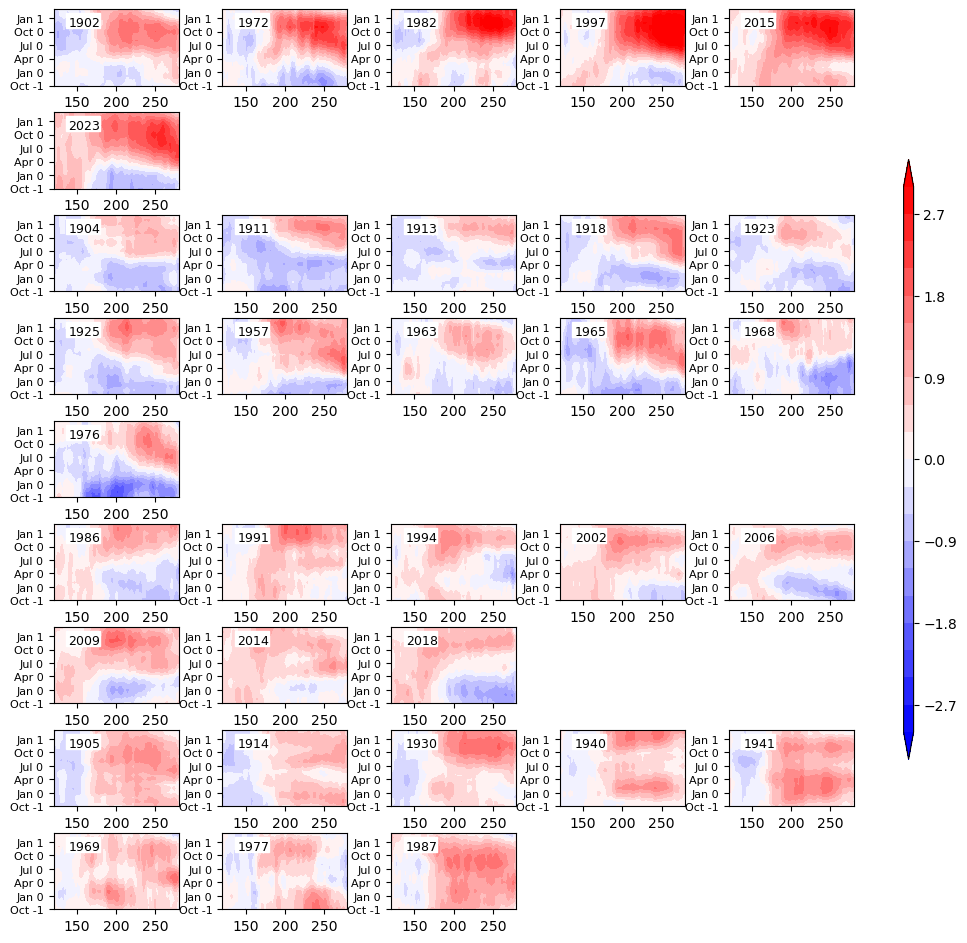

In [78]:
fig = plt.figure(figsize=(10, 10))
order = [1, 3, 0, 2]
nino_label = [label[c_label == order[i]] for i in range(4)]
N = 2+3+2+2
l = 0
months_str = np.array(["Oct -1", "Nov -1", "Dec -1", "Jan 0", "Feb 0", "Mar 0", "Apr 0", "May 0", "Jun 0", "Jul 0", "Aug 0", "Sep 0", "Oct 0", "Nov 0", "Dec 0", "Jan 1", "Feb 1", "Mar 1"])
months_val = np.arange(18)
lev = np.linspace(-3, 3, 21)
for i in range(n_clusters):
    nino = nino_label[i]
    for j in range(len(nino)):
        start = events[nino[j]].values.astype('datetime64[M]') - np.timedelta64(3, 'M')
        end = events[nino[j]].values.astype('datetime64[M]') + np.timedelta64(14, 'M')
        s = sst_an.loc[start:end]
        l += 1
        ax = fig.add_subplot(N, 5, l)
        cb = ax.contourf(lon, months_val, s, cmap='bwr', levels=lev, extend='both')
        left, bottom, width, height = 0.1, 0.75, 0.27, 0.2
        box = Rectangle((left, bottom), width, height, transform=ax.transAxes, facecolor='white', edgecolor='white', zorder=1)
        ax.add_patch(box)
        text = events[nino[j]].values.astype('datetime64[Y]')
        ax.text(0.12, 0.78, text, transform=ax.transAxes, fontsize=9)
        ax.set_yticks(np.arange(0, 18, 3))
        ax.set_yticklabels(months_str[np.arange(0, 18, 3)], fontsize=8) 
    m = l % 5
    if m != 0:
        l = (l//5+1)*5

cbaxes = fig.add_axes([0.9, 0.2, 0.01, 0.6])
cb = plt.colorbar(cb, cax=cbaxes, orientation="vertical")
fig.subplots_adjust(left=0.05, right=0.85, bottom=0.05, top=0.95, wspace=0.35, hspace=0.35)  
fig.savefig('./pic/el_nino.png', dpi=300)


In [70]:
ssta = np.zeros((n_clusters, 18, len(lon)))
for n in range(n_clusters):
    cluster0 = label[c_label == n]
    for i in range(len(cluster0)):
        start = events[cluster0[i]].values.astype('datetime64[M]') - np.timedelta64(3, 'M')
        end = events[cluster0[i]].values.astype('datetime64[M]') + np.timedelta64(14, 'M')
        ssta[n, :, :] += sst_an.loc[start:end]
    ssta[n, :, :] /= len(cluster0)

In [8]:
c_label

array([1, 3, 2, 3, 3, 2, 3, 3, 3, 2, 2, 2, 3, 3, 3, 3, 2, 1, 3, 2, 1, 0,
       2, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1])

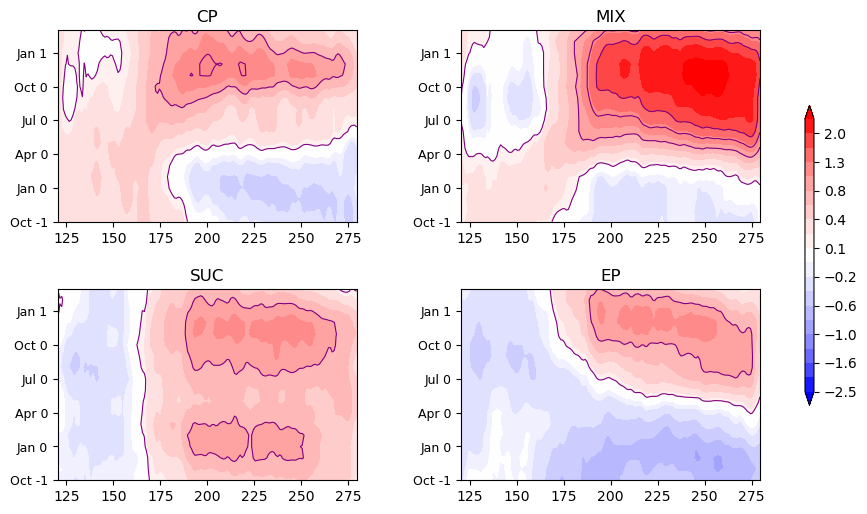

In [77]:
fig, axs = plt.subplots(2, 2, figsize=(9, 5))
months = np.arange(0, 17)
levels = np.arange(0.2, 2.1, 0.2)
levels = np.r_[-levels[::-1], levels]
levels = np.array([-2.5, -2, -1.6, -1.3, -1, -0.8, -0.6, -0.4, -0.2, -0.1])
levels = np.r_[levels, -levels[::-1]]
months_str = np.array(["Oct -1", "Nov -1", "Dec -1", "Jan 0", "Feb 0", "Mar 0", "Apr 0", "May 0", "Jun 0", "Jul 0", "Aug 0", "Sep 0", "Oct 0", "Nov 0", "Dec 0", "Jan 1", "Feb 1", "Mar 1"])
months_val = np.arange(18)
titles = ['CP', 'MIX', 'SUC', 'EP']
for i, ax in enumerate(axs.flatten()[:n_clusters]):
    cb = ax.contourf(lon, months_val, ssta[i], cmap='bwr', levels=levels, extend='both')
    ax.contour(lon, months_val, ssta[i], colors='purple', linewidths=0.8, levels=[0.1, 0.8, 1.2, 1.6])
    ax.set_yticks(np.arange(0, 18, 3))
    ax.set_yticklabels(months_str[np.arange(0, 18, 3)], fontsize=9) 
    ax.set_title(titles[i], fontsize=12)

cbaxes = fig.add_axes([0.9, 0.2, 0.01, 0.6])
cb = plt.colorbar(cb, cax=cbaxes, orientation="vertical")
fig.subplots_adjust(left=0.07, right=0.85, bottom=0.05, top=0.95, wspace=0.35, hspace=0.35)  
fig.savefig('./pic/el_nino_com.png', dpi=300)

In [3]:
ohc = xr.open_dataset(r'C:\Users\jiuwe\study\data\necp\monthly\OHC.0-700m.seasona.nc').h18_hc.loc['1955':'2024', :, 120:280:2]
uwnd = xr.open_dataset(r'C:\Users\jiuwe\study\data\era5\monthly\uwnd.mon.nc').u.loc['1955':'2024', 850, 40:-40, 120:280:2]
lon = uwnd.lon
lat = uwnd.lat
ohc = ohc.interp(lat=lat, lon=lon)

cp = np.fromfile('./data/CP.txt', dtype='<U48').astype('datetime64[M]')
ep = np.fromfile('./data/EP.txt', dtype='<U48').astype('datetime64[M]')
mix = np.fromfile('./data/MIX.txt', dtype='<U48').astype('datetime64[M]')
suc = np.fromfile('./data/SUC.txt', dtype='<U48').astype('datetime64[M]')
cp = cp[cp >= np.datetime64('1955-01')]
ep = ep[ep >= np.datetime64('1955-01')]
mix = mix[mix >= np.datetime64('1955-01')]
suc = suc[suc >= np.datetime64('1955-01')]
events = [mix, ep, cp, suc]


u_cli = uwnd.groupby(uwnd.time.dt.month).mean()
u_ano = uwnd.groupby(uwnd.time.dt.month) - u_cli
o_cli = ohc.groupby(ohc.time.dt.month).mean()
o_ano = ohc.groupby(ohc.time.dt.month) - o_cli


o_ano = o_ano.loc[:, 5:-5, :].mean(dim='lat')
u_ano = u_ano.loc[:, 5:-5, :].mean(dim='lat')

In [4]:
u_elnino = np.zeros((4, 18, len(lon)))
o_elnino = np.zeros((4, 6, len(lon)))
for i in range(4):
    nino = events[i]
    for j in range(len(nino)):
        start = nino[j] - np.timedelta64(3, 'M')
        end = nino[j] + np.timedelta64(14, 'M')
        
        # print(start)
        u_elnino[i] += u_ano.loc[start:end, :].values
        
        o_elnino[i] += o_ano.loc[start:end, :].values
        
    u_elnino[i] /= len(nino)
    o_elnino[i] /= len(nino)

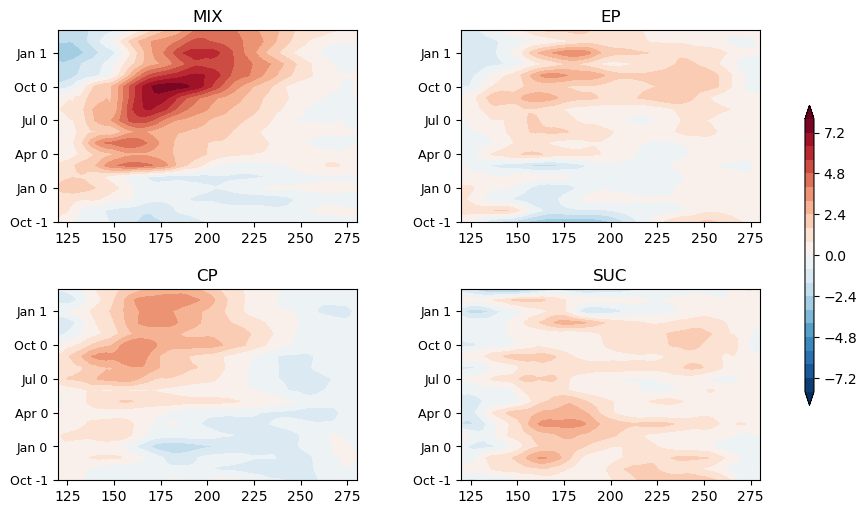

In [12]:
fig, axs = plt.subplots(2, 2, figsize=(9, 5))
month1 = np.arange(0, 18)
month2 = np.arange(0, 18, 3)
months_str = np.array(["Oct -1", "Nov -1", "Dec -1", "Jan 0", "Feb 0", "Mar 0", "Apr 0", "May 0", "Jun 0", "Jul 0", "Aug 0", "Sep 0", "Oct 0", "Nov 0", "Dec 0", "Jan 1", "Feb 1", "Mar 1"])
titles = ['MIX', 'EP', 'CP', 'SUC']
for i, ax in enumerate(axs.flatten()):
    cb = ax.contourf(lon, month1, u_elnino[i], cmap='RdBu_r', levels=np.linspace(-8, 8, 21), extend='both')
    # ax.contour(lon, month2, o_elnino[i], colors='k', linewidths=0.8, levels=11)
    ax.set_yticks(np.arange(0, 18, 3))
    ax.set_yticklabels(months_str[np.arange(0, 18, 3)], fontsize=9) 
    ax.set_title(titles[i], fontsize=12)
    
cbaxes = fig.add_axes([0.9, 0.2, 0.01, 0.6])
cb = plt.colorbar(cb, cax=cbaxes, orientation="vertical")
fig.subplots_adjust(left=0.07, right=0.85, bottom=0.05, top=0.95, wspace=0.35, hspace=0.35) 
fig.savefig('./pic/uwnd-time.png', dpi=300)

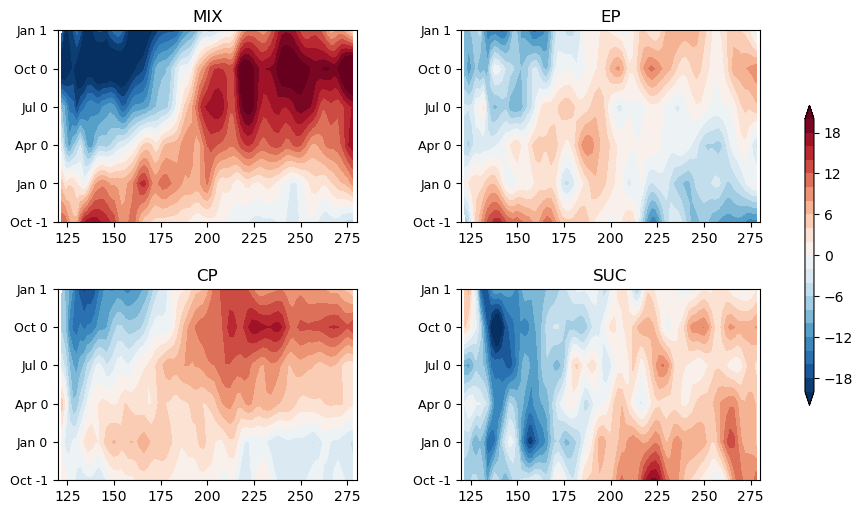

In [13]:
fig, axs = plt.subplots(2, 2, figsize=(9, 5))
month1 = np.arange(0, 18)
month2 = np.arange(0, 18, 3)
months_str = np.array(["Oct -1", "Nov -1", "Dec -1", "Jan 0", "Feb 0", "Mar 0", "Apr 0", "May 0", "Jun 0", "Jul 0", "Aug 0", "Sep 0", "Oct 0", "Nov 0", "Dec 0", "Jan 1", "Feb 1", "Mar 1"])
titles = ['MIX', 'EP', 'CP', 'SUC']
for i, ax in enumerate(axs.flatten()):
    cb = ax.contourf(lon, month2, o_elnino[i], cmap='RdBu_r', levels=np.linspace(-20, 20, 21), extend='both')
    # ax.contour(lon, month2, o_elnino[i], colors='k', linewidths=0.8, levels=11)
    ax.set_yticks(np.arange(0, 18, 3))
    ax.set_yticklabels(months_str[np.arange(0, 18, 3)], fontsize=9) 
    ax.set_title(titles[i], fontsize=12)
    
cbaxes = fig.add_axes([0.9, 0.2, 0.01, 0.6])
cb = plt.colorbar(cb, cax=cbaxes, orientation="vertical")
fig.subplots_adjust(left=0.07, right=0.85, bottom=0.05, top=0.95, wspace=0.35, hspace=0.35) 
fig.savefig('./pic/ohc-time.png', dpi=300)

In [69]:
uwnd = xr.open_dataset(r'C:\Users\jiuwe\study\data\era5\monthly\uwnd.mon.nc').u.loc[:, 200, 40:-40, 120:280:2]
vwnd = xr.open_dataset(r'C:\Users\jiuwe\study\data\era5\monthly\vwnd.mon.nc').v.loc[:, 200, 40:-40, 120:280:2]
wwnd = xr.open_dataset(r'C:\Users\jiuwe\study\data\era5\monthly\wwnd.mon.nc').w.loc[:, 200, 40:-40, 120:280:2]

cp = np.fromfile('./data/CP.txt', dtype='<U48').astype('datetime64[M]')
ep = np.fromfile('./data/EP.txt', dtype='<U48').astype('datetime64[M]')
mix = np.fromfile('./data/MIX.txt', dtype='<U48').astype('datetime64[M]')
suc = np.fromfile('./data/SUC.txt', dtype='<U48').astype('datetime64[M]')
cp = cp[cp >= np.datetime64('1940-01')]
ep = ep[ep >= np.datetime64('1940-01')]
mix = mix[mix >= np.datetime64('1940-01')]
suc = suc[suc >= np.datetime64('1940-01')]
events = [mix, ep, cp, suc]

level = uwnd.level
lon = uwnd.lon
lat = uwnd.lat


In [70]:
u_cli = uwnd.groupby(uwnd.time.dt.month).mean()
u_ano = uwnd.groupby(uwnd.time.dt.month) - u_cli
v_cli = vwnd.groupby(vwnd.time.dt.month).mean()
v_ano = vwnd.groupby(vwnd.time.dt.month) - v_cli
w_cli = wwnd.groupby(wwnd.time.dt.month).mean()
w_ano = wwnd.groupby(wwnd.time.dt.month) - w_cli


In [71]:
u_elnino = np.zeros((4, 4, len(lat), len(lon)))
v_elnino = np.zeros((4, 4, len(lat), len(lon)))
w_elnino = np.zeros((4, 4, len(lat), len(lon)))
for i in range(4):
    nino = events[i]
    for j in range(len(nino)):
        start = nino[j]
        u_elnino[i, 0] += u_ano.loc[start:start+np.timedelta64(2, 'M'), :, :].mean(dim='time').values
        u_elnino[i, 1] += u_ano.loc[start+np.timedelta64(3, 'M'):start+np.timedelta64(5, 'M'), :, :].mean(dim='time').values
        u_elnino[i, 2] += u_ano.loc[start+np.timedelta64(6, 'M'):start+np.timedelta64(8, 'M'), :, :].mean(dim='time').values
        u_elnino[i, 3] += u_ano.loc[start+np.timedelta64(9, 'M'):start+np.timedelta64(11, 'M'), :, :].mean(dim='time').values

        v_elnino[i, 0] += v_ano.loc[start:start+np.timedelta64(2, 'M'), :, :].mean(dim='time').values
        v_elnino[i, 1] += v_ano.loc[start+np.timedelta64(3, 'M'):start+np.timedelta64(5, 'M'), :, :].mean(dim='time').values
        v_elnino[i, 2] += v_ano.loc[start+np.timedelta64(6, 'M'):start+np.timedelta64(8, 'M'), :, :].mean(dim='time').values
        v_elnino[i, 3] += v_ano.loc[start+np.timedelta64(9, 'M'):start+np.timedelta64(11, 'M'), :, :].mean(dim='time').values
        
        w_elnino[i, 0] += w_ano.loc[start:start+np.timedelta64(2, 'M'), :, :].mean(dim='time').values
        w_elnino[i, 1] += w_ano.loc[start+np.timedelta64(3, 'M'):start+np.timedelta64(5, 'M'), :, :].mean(dim='time').values
        w_elnino[i, 2] += w_ano.loc[start+np.timedelta64(6, 'M'):start+np.timedelta64(8, 'M'), :, :].mean(dim='time').values
        w_elnino[i, 3] += w_ano.loc[start+np.timedelta64(9, 'M'):start+np.timedelta64(11, 'M'), :, :].mean(dim='time').values
    u_elnino[i] /= len(nino)
    v_elnino[i] /= len(nino)
    w_elnino[i] /= len(nino)
# div_elnino = np.gradient(u_elnino, lon.values, axis=3) + np.gradient(v_elnino, lat.values, axis=2) 

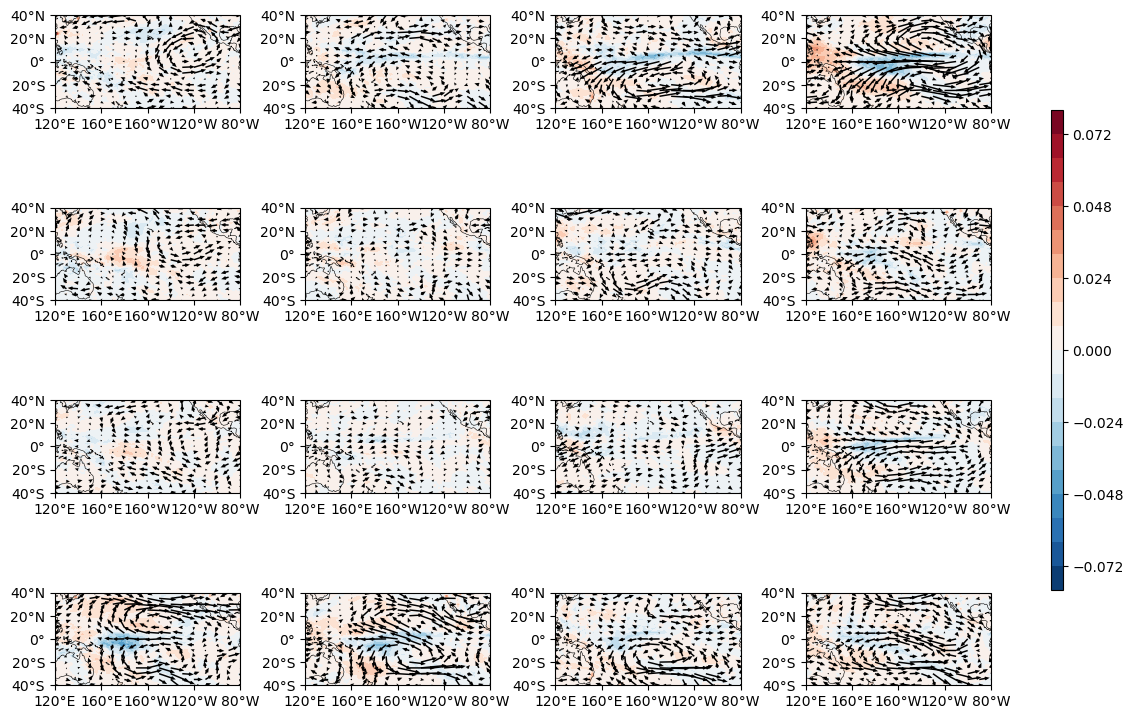

In [74]:
fig, axs = plt.subplots(4, 4, figsize=(12, 8), subplot_kw={'projection': ccrs.PlateCarree(central_longitude=135)})
skip = 5
for i in range(4):
    for j in range(4):
        u = u_elnino[i, j]
        v = v_elnino[i, j]
        w = w_elnino[i, j]
        ax = axs[i, j]
        ax.set_extent([120, 280, -40, 40], crs=ccrs.PlateCarree())
        ax.coastlines(lw=0.4, color='k')
        cb = ax.contourf(lon, lat, w, cmap='RdBu_r', levels=np.linspace(-8, 8, 21)/100, transform=ccrs.PlateCarree())
        ax.quiver(lon[::skip], lat[::skip], u[::skip, ::skip], v[::skip, ::skip], scale=70, width=0.008, headwidth=2.5, headlength=3, headaxislength=3.5, transform=ccrs.PlateCarree())
        ax.set_yticks([-40, -20, 0, 20, 40], crs=ccrs.PlateCarree())
        ax.set_xticks(np.arange(120, 281, 40), crs=ccrs.PlateCarree())   
        ax.xaxis.set_major_formatter(LongitudeFormatter(zero_direction_label=True))
        ax.yaxis.set_major_formatter(LatitudeFormatter())
        
cbaxes = fig.add_axes([0.9, 0.2, 0.01, 0.6])
cb = plt.colorbar(cb, cax=cbaxes, orientation="vertical")
fig.subplots_adjust(left=0.07, right=0.85, bottom=0.05, top=0.95, wspace=0.35, hspace=0.35) 
fig.savefig('./pic/uv 200.png', dpi=300)

In [22]:
uwnd = xr.open_dataset(r'C:\Users\jiuwe\study\data\era5\monthly\uwnd.mon.nc').u.loc[:, :, 40:-40, 120:280:2]
vwnd = xr.open_dataset(r'C:\Users\jiuwe\study\data\era5\monthly\vwnd.mon.nc').v.loc[:, :, 40:-40, 120:280:2]
wwnd = xr.open_dataset(r'C:\Users\jiuwe\study\data\era5\monthly\wwnd.mon.nc').w.loc[:, :, 40:-40, 120:280:2]

cp = np.fromfile('./data/CP.txt', dtype='<U48').astype('datetime64[M]')
ep = np.fromfile('./data/EP.txt', dtype='<U48').astype('datetime64[M]')
mix = np.fromfile('./data/MIX.txt', dtype='<U48').astype('datetime64[M]')
suc = np.fromfile('./data/SUC.txt', dtype='<U48').astype('datetime64[M]')
cp = cp[cp >= np.datetime64('1940-01')]
ep = ep[ep >= np.datetime64('1940-01')]
mix = mix[mix >= np.datetime64('1940-01')]
suc = suc[suc >= np.datetime64('1940-01')]
events = [mix, ep, cp, suc]
level = uwnd.level
lon = uwnd.lon
lat = uwnd.lat

uwnd = uwnd.loc[:, :, 5:-5, :].mean(dim='lat')
wwnd = wwnd.loc[:, :, 5:-5, :].mean(dim='lat')

In [50]:
xr.open_dataset(r'C:\Users\jiuwe\study\data\era5\monthly\wwnd.mon.nc')

<xarray.Dataset>
Dimensions:  (time: 1020, level: 11, lat: 81, lon: 161)
Coordinates:
  * time     (time) datetime64[ns] 1940-01-01 1940-02-01 ... 2024-12-01
  * level    (level) float64 1e+03 925.0 850.0 800.0 ... 500.0 400.0 300.0 200.0
  * lat      (lat) float64 40.0 39.0 38.0 37.0 36.0 ... -37.0 -38.0 -39.0 -40.0
  * lon      (lon) float64 120.0 121.0 122.0 123.0 ... 277.0 278.0 279.0 280.0
Data variables:
    w        (time, level, lat, lon) float32 ...

In [51]:
u_cli = uwnd.groupby(uwnd.time.dt.month).mean()
u_ano = uwnd.groupby(uwnd.time.dt.month) - u_cli

w_cli = wwnd.groupby(wwnd.time.dt.month).mean()
w_ano = wwnd.groupby(wwnd.time.dt.month) - w_cli

# w_cli = uwnd.groupby(wwnd.time.dt.month).mean()
# w_ano = uwnd.groupby(wwnd.time.dt.month) - w_cli


In [43]:
w_ano = wwnd

In [52]:
# u_ano = u_ano.loc[:, :, 5:-5, :].mean(dim='lat')
# w_ano = w_ano.loc[:, :-1, 5:-5, :].mean(dim='lat')
u_elnino = np.zeros((4, 4, len(level), len(lon)))
w_elnino = np.zeros((4, 4, len(level), len(lon)))
for i in range(4):
    nino = events[i]
    for j in range(len(nino)):
        start = nino[j]
        # print(start)
        u_elnino[i, 0] += u_ano.loc[start:start+np.timedelta64(2, 'M'), :, :].mean(dim='time').values
        u_elnino[i, 1] += u_ano.loc[start+np.timedelta64(3, 'M'):start+np.timedelta64(5, 'M'), :, :].mean(dim='time').values
        u_elnino[i, 2] += u_ano.loc[start+np.timedelta64(6, 'M'):start+np.timedelta64(8, 'M'), :, :].mean(dim='time').values
        u_elnino[i, 3] += u_ano.loc[start+np.timedelta64(9, 'M'):start+np.timedelta64(11, 'M'), :, :].mean(dim='time').values
        
        w_elnino[i, 0] += w_ano.loc[start:start+np.timedelta64(2, 'M'), :, :].mean(dim='time').values[:-1, :]
        w_elnino[i, 1] += w_ano.loc[start+np.timedelta64(3, 'M'):start+np.timedelta64(5, 'M'), :, :].mean(dim='time').values[:-1, :]
        w_elnino[i, 2] += w_ano.loc[start+np.timedelta64(6, 'M'):start+np.timedelta64(8, 'M'), :, :].mean(dim='time').values[:-1, :]
        w_elnino[i, 3] += w_ano.loc[start+np.timedelta64(9, 'M'):start+np.timedelta64(11, 'M'), :, :].mean(dim='time').values[:-1, :]
    u_elnino[i] /= len(nino)
    w_elnino[i] /= len(nino)
    


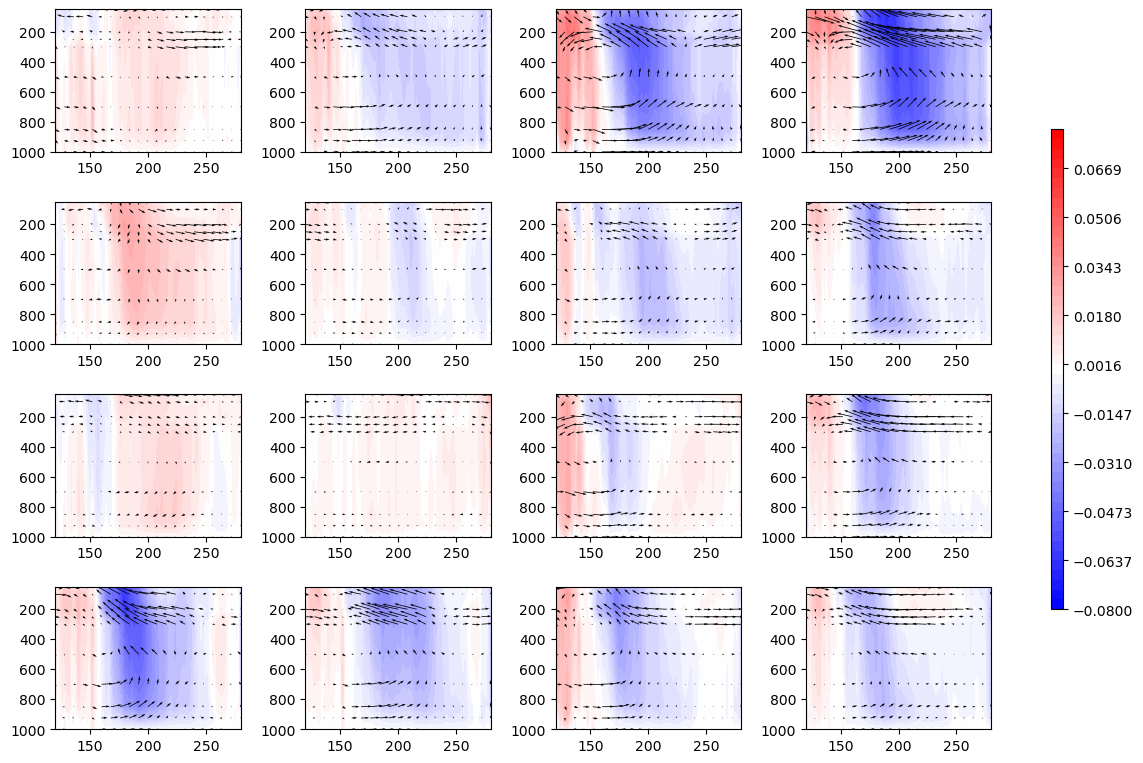

In [54]:
fig, axs = plt.subplots(4, 4, figsize=(12, 8))
for i in range(4):
    for j in range(4):
        u = u_elnino[i, j]
        w = w_elnino[i, j]
        ax = axs[i, j]
        cb = ax.contourf(lon, level, w, cmap='bwr', levels=np.linspace(-8, 8)/100) 
        ax.quiver(lon[::4], level, u[:, ::4], -w[:, ::4]*50, scale=50)
        ax.invert_yaxis()
        
cbaxes = fig.add_axes([0.9, 0.2, 0.01, 0.6])
cb = plt.colorbar(cb, cax=cbaxes, orientation="vertical")
fig.subplots_adjust(left=0.07, right=0.85, bottom=0.05, top=0.95, wspace=0.35, hspace=0.35) 
fig.savefig('./pic/walker.png', dpi=300)

In [384]:
ds = xr.open_dataset(r'C:\Users\jiuwe\study\data\necp\monthly\heat_content_anomaly_0-700_seasonal.nc', decode_times=False)
units = ds['time'].attrs['units']
base_date = pd.Timestamp('1955-01-01')
months = ds['time'].values.astype(int)

# DateOffset 支持 month 偏移
dates = [base_date + pd.DateOffset(months=int(m)) for m in months]
ds['time'] = ('time', pd.to_datetime(dates))

ohc_org = ds.h18_hc.loc[:, 0, -40:40]

o1 = ohc_org.loc[:, :, -180:0]
o2 = ohc_org.loc[:, :, 0:180]
o1 = o1.assign_coords(lon=o1.lon.values+360)
ohc = xr.concat([o2, o1], dim='lon')
ohc.to_netcdf(r'C:\Users\jiuwe\study\data\necp\monthly\OHC.0-700m.seasona.nc')

In [2]:
# Walker
# ds_u = xr.open_dataset(r'E:\data\era5\monthly\ERA5-u_component_of_wind-1940_202602.nc')
# ds_v = xr.open_dataset(r'E:\data\era5\monthly\ERA5-v_component_of_wind-1940_202602.nc')
ds_w = xr.open_dataset(r'C:\Users\jiuwe\study\data\era5\monthly\ERA5-vertical_velocity-202506.nc')
# ds_p = xr.open_dataset(r'E:\data\era5\monthly\ERA5-mean_sea_level_pressure-1940_202412.nc')



In [ ]:
# ds_u.sel(time=slice('1940', '2024')).rename({'pressure_level':'level', 'latitude':'lat', 'longitude':'lon'}).to_netcdf(r'C:\Users\jiuwe\study\data\era5\monthly\uwnd.mon.nc')
# ds_v.sel(time=slice('1940', '2024')).rename({'pressure_level':'level', 'latitude':'lat', 'longitude':'lon'}).to_netcdf(r'C:\Users\jiuwe\study\data\era5\monthly\vwnd.mon.nc')
# ds_p.sel(time=slice('1940', '2024')).rename({'latitude':'lat', 'longitude':'lon'}).to_netcdf(r'C:\Users\jiuwe\study\data\era5\monthly\slp.mon.nc')
ds_w.sel(valid_time=slice('1940', '2024')).rename({'valid_time':'time', 'pressure_level':'level', 'latitude':'lat', 'longitude':'lon'}).to_netcdf(r'C:\Users\jiuwe\study\data\era5\monthly\wwnd.mon.nc')

In [3]:
w = ds_w.sel(valid_time=slice('1940', '2024')).rename({'valid_time':'time', 'pressure_level':'level', 'latitude':'lat', 'longitude':'lon'}).w

In [9]:
w.loc[:, :, 40:-40, 120:280].to_netcdf(r'C:\Users\jiuwe\study\data\era5\monthly\wwnd.mon.nc')